# Homework 3

## Question

When comparing predictions $\hat{y_i}$ with observed values $y_i$, we need to choose a way to measure the error.  Two possibilities are mean squared error (MSE), $\frac{1}{n} \sum (\hat{y_i}- y_i)^2$ and mean absolute error (MAE), $\frac{1}{n} \sum |\hat{y_i} - y_i|$, where $n$ is the number of observations.

* Write a function `mse(prediction, target)` which returns the mean of the squared differences between `prediction` and `target`.  You may assume these inputs will be NumPy arrays of the same length.  (If you square a NumPy array, it will square each individual entry.)
* Write a function `mae(prediction, target)` which returns the mean of the absolute differences.  (The NumPy function `np.abs` computes the absolute value of each element in an array.)
* Both functions should use NumPy arithmetic, without a for loop.  The inputs might be arrays, or one input might be a single number which gets broadcast to an array.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

In [18]:
def mse(prediction, target):
    return ((prediction - target) ** 2).mean()

def mae(prediction, target):
    return np.abs(prediction - target).mean()

In [19]:
a = np.array([1, 2, 3])
b = np.array([2, 2, 5])

mse(a, b)

np.float64(1.6666666666666667)

In [5]:
mae(a, b)

np.float64(1.0)

In [20]:
mse(a, 2)

np.float64(0.6666666666666666)

## Question

Here we'll generate some random data that will correspond to our target.  We will form the predictions later.

* Instantiate a random number generator in NumPy.  Use a seed (your choice) to have reproducible numbers.
* Fix a number of observations `n`, your choice (but less than 10,000 is probably best).
* Define our target data as follows.  Read through the code and try to understand all pieces of it.
```
x = np.linspace(1, 5, n)
factor = np.exp(rng.normal(loc=0, scale=0.8, size=n))
y = (2*x + 1)*factor
```
* Draw a scatterplot using Matplotlib of this data.

Text(0, 0.5, 'y')

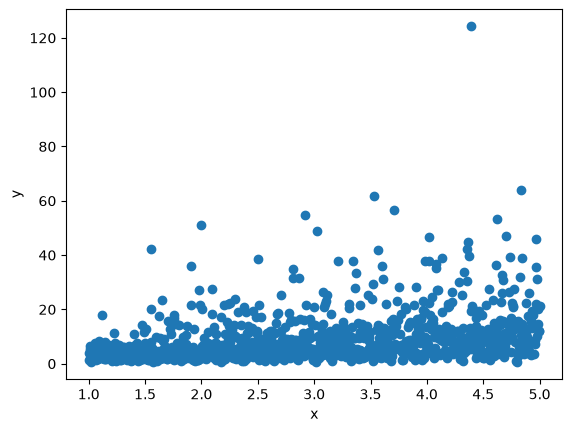

In [9]:
rng = np.random.default_rng(seed = 42)
n = 1000

x = np.linspace(1, 5, n)
factor = np.exp(rng.normal(loc = 0, scale = 0.8, size = n))
y = (2 * x + 1) * factor

fig, ax = plt.subplots()
ax.scatter(x, y)
ax.set_xlabel("x")
ax.set_ylabel("y")

## Question

Here we'll look for the line that gives us the best predictions.  Our line will have the form `prediction = w*x + b`.  The number `w` is the slope (also called a weight), and `b` is the intercept (also called a bias).

To search for a line of best fit, we will try many choices of `w` and `b`.  We want to pair every choice of `w` with every choice of `b`, using the `product` function from the `itertools` library is a convenient way to do this.  (It works a little like `zip`, but where `zip` pairs first element with first element, second element with second element, `product` instead forms every possible pair.)

* Before running the following code, predict what values will be in `example_pairs`.  Then run it and check your prediction.

```python
from itertools import product

example_pairs = list(product([1, 2], [10, 20, 30]))
```

* Now use the following candidate weights and biases.  Use `product` and `list` to make a list named `pairs` containing every weight-bias pair.  How many pairs are there?

```python
weights = np.linspace(0, 5, 101)
biases = np.linspace(-2, 4, 121)
```

In [11]:
example_pairs = list(product([1, 2], [10, 20, 30]))
example_pairs

[(1, 10), (1, 20), (1, 30), (2, 10), (2, 20), (2, 30)]

In [12]:
weights = np.linspace(0, 5, 101)
biases = np.linspace(-2, 4, 121)

pairs = list(product(weights, biases))
len(pairs)

12221

* Make two empty lists named `mae_losses` and `mse_losses`.  For each pair in `pairs`, compute the predictions and append the corresponding losses to these lists.  (Make sure the ordering of the two lists matches the order in `pairs`, otherwise what's below won't work.)

In [21]:
mae_losses = []
mse_losses = []

for w, b in pairs:
    prediction = w * x + b
    mae_losses.append(mae(prediction, y))
    mse_losses.append(mse(prediction, y))
    

In [22]:
len(mae_losses), len(mse_losses)

(12221, 12221)

## Question

Now we will find the best line under each definition of error.  Both the slope and the intercept are allowed to change.

* The function `np.argmin` gives the position of the smallest entry in a list or array.  For example, `np.argmin([4, 6, 1, 3])` returns 2.  Use it to find the position of the smallest MAE, then use that position to get the corresponding pair from `pairs`.  Name this pair `best_mae`.
* Do the same for MSE, naming the pair `best_mse`.
* Report the equation of each line in a markdown cell.  Be sure to indicate which line is best for MAE, and which is best for MSE. Are the two lines the same?  Which is closer to the original line that the data came from?

In [23]:
best_mae = pairs[np.argmin(mae_losses)]
best_mse = pairs[np.argmin(mse_losses)]

best_mae

(np.float64(2.15), np.float64(0.6000000000000001))

In [24]:
best_mse

(np.float64(2.7), np.float64(1.25))

The best line for MAE is 2.15.

The best line for MSE is 2.7. 

The two lines aren't the same. The MAE line should be close to the original line, while the MSE should have a bigger slope and itnercept. 

* Using Matplotlib, on the same axes, make a scatterplot of the data, then the line corresponding to MAE best fit in red using the format abbreviation 'r', then the line corresponding to MSE best fit in black using the format abbreviation 'k'.
* Using the `label` keyword argument, indicate which line is for MAE and which line is for MSE.  After calling `ax.scatter` once and `ax.plot` twice in the same cell, use `ax.legend()` to display the legend.
* From the image, does the MAE best fit line or the MSE best fit line seem more influenced by the large y values?

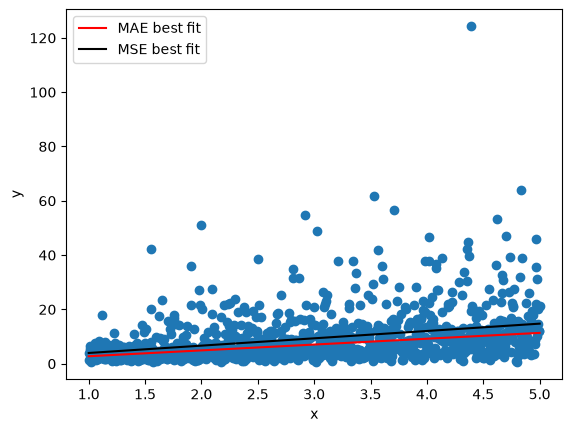

In [25]:
fig, ax = plt.subplots()

ax.scatter(x, y)
ax.plot(x, best_mae[0]*x + best_mae[1], 'r', label="MAE best fit")
ax.plot(x, best_mse[0]*x + best_mse[1], 'k', label="MSE best fit")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()

## Submission

* When you've completed this assignment, save your work, commit and push your changes to GitHub (including this notebook and any changes to `requirements.txt`), and share the GitHub directory through Gradescope, linked from the left side of Canvas.